# 2. Paired MEA profiles — Figure 3 plots

Paired t-SNE, representative Base–Treat trajectories, and standardized changes.

## Load dataset

In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "mea_ml" / "io.py").is_file()
)
sys.path.insert(0, str(PROJECT_ROOT))

from mea_ml.plotting import save_png
from typing import List, Tuple
import re

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from IPython.display import display

from mea_ml.io import ROOT as PROJECT_ROOT
ROOT_DIR = PROJECT_ROOT
EXPORT_ROOT = PROJECT_ROOT / "results"
DATASET_DIR = EXPORT_ROOT / "01_dataset"
OUT_DIR = EXPORT_ROOT / "02_descriptive"
FIG3_DIR = OUT_DIR

for d in [OUT_DIR, FIG3_DIR]:
    d.mkdir(parents=True, exist_ok=True)

BUNDLE_PATH = DATASET_DIR / "training_bundle.joblib"
PAIRED_PATH = DATASET_DIR / "paired_mea_features_zero_filled.csv"
FEATURE_MANIFEST_PATH = DATASET_DIR / "feature_manifest.csv"
GROUP_MANIFEST_PATH = DATASET_DIR / "group_manifest.csv"

required = [BUNDLE_PATH, PAIRED_PATH, FEATURE_MANIFEST_PATH, GROUP_MANIFEST_PATH]
missing = [str(p.relative_to(PROJECT_ROOT)) for p in required if not p.exists()]
if missing:
    raise FileNotFoundError("Missing required files:\n" + "\n".join(missing))

bundle = joblib.load(BUNDLE_PATH)
paired_df = pd.read_csv(PAIRED_PATH)
feature_manifest = pd.read_csv(FEATURE_MANIFEST_PATH)
group_manifest = pd.read_csv(GROUP_MANIFEST_PATH)

retained_raw_features = list(bundle["retained_raw_features"])
print("Loaded bundle:", BUNDLE_PATH.relative_to(PROJECT_ROOT))
print("Paired organoids:", paired_df.shape)
print("Retained raw features:", len(retained_raw_features))


Loaded bundle: results/01_dataset/training_bundle.joblib
Paired organoids: (90, 94)
Retained raw features: 44


## Displayed features

In [2]:
FIG3_SLOPE_FEATURES = [
    "Mean Firing Rate (Hz)",
    "Width at Half Height of Normalized Cross-Correlation",
    "Number of Network Bursts",
    "ISI Coefficient of Variation - Avg",
]

FIG3_HEATMAP_FEATURES = [
    "Mean Firing Rate (Hz)",
    "Number of Bursts",
    "Number of Network Bursts",
    "Synchrony Index",
    "Width at Half Height of Normalized Cross-Correlation",
    "ISI Coefficient of Variation - Avg",
]

BASE_POINT_COLOR = "#6b7280"
TREAT_POINT_COLOR = "#d97706"
LINE_COLOR = "#9ca3af"
HEATMAP_CMAP = "coolwarm"

CLASS_COLOR = {"Negative": "#1f77b4", "Positive": "#d62728"}
CLASS_TO_INT = {"Negative": 0, "Positive": 1}

DISPLAY_TITLE_MAP = {
    "Mean Firing Rate (Hz)": "MFR",
    "Width at Half Height of Normalized Cross-Correlation": "NCC width",
    "Number of Network Bursts": "log1p(NB)",
    "ISI Coefficient of Variation - Avg": "ISI CV",
}

print("Figure 3 slope features:", FIG3_SLOPE_FEATURES)
print("Figure 3 heatmap features:", FIG3_HEATMAP_FEATURES)

TSNE_RANDOM_STATE = 0
TSNE_INIT = "pca"
TSNE_LEARNING_RATE = "auto"


Figure 3 slope features: ['Mean Firing Rate (Hz)', 'Width at Half Height of Normalized Cross-Correlation', 'Number of Network Bursts', 'ISI Coefficient of Variation - Avg']
Figure 3 heatmap features: ['Mean Firing Rate (Hz)', 'Number of Bursts', 'Number of Network Bursts', 'Synchrony Index', 'Width at Half Height of Normalized Cross-Correlation', 'ISI Coefficient of Variation - Avg']


## Plot functions

In [3]:
def feature_columns(feature: str) -> Tuple[str, str]:
    return f"Base::{feature}", f"Treat::{feature}"

def use_log1p_for_feature(feature: str) -> bool:
    return feature in {"Number of Spikes", "Number of Bursts", "Number of Network Bursts", "Network Burst Percentage"}

def standardized_delta_matrix(features: List[str]) -> Tuple[pd.DataFrame, List[str]]:
    cols, feature_names = [], []
    for feat in features:
        base_col, treat_col = feature_columns(feat)
        x = pd.to_numeric(paired_df[treat_col], errors="coerce") - pd.to_numeric(paired_df[base_col], errors="coerce")
        x = x.astype(float)
        mu = np.nanmean(x)
        sd = np.nanstd(x, ddof=0)
        z = np.zeros(len(x), dtype=float) if (not np.isfinite(sd) or sd == 0) else (x - mu) / sd
        cols.append(z)
        feature_names.append(feat)
    mat = pd.DataFrame(np.vstack(cols), index=feature_names, columns=paired_df.index.astype(str))
    return mat, feature_names

def standardized_state_matrices(features: List[str]) -> Tuple[pd.DataFrame, pd.DataFrame]:
    base_blocks, treat_blocks, feature_names = [], [], []
    for feat in features:
        base_col, treat_col = feature_columns(feat)
        b = pd.to_numeric(paired_df[base_col], errors="coerce").astype(float)
        t = pd.to_numeric(paired_df[treat_col], errors="coerce").astype(float)
        both = pd.concat([b, t], axis=0)
        mu = np.nanmean(both)
        sd = np.nanstd(both, ddof=0)
        if not np.isfinite(sd) or sd == 0:
            bz = np.zeros(len(b), dtype=float)
            tz = np.zeros(len(t), dtype=float)
        else:
            bz = (b - mu) / sd
            tz = (t - mu) / sd
        base_blocks.append(bz.to_numpy())
        treat_blocks.append(tz.to_numpy())
        feature_names.append(feat)
    base_df = pd.DataFrame(np.vstack(base_blocks).T, columns=feature_names)
    treat_df = pd.DataFrame(np.vstack(treat_blocks).T, columns=feature_names)
    return base_df, treat_df

def class_colored_slope_plot(ax, feature: str, show_legend: bool = False):
    base_col, treat_col = feature_columns(feature)
    dat = paired_df[["class", "pair_stem", "group_id", "well", base_col, treat_col]].copy()
    dat["base_value"] = dat[base_col]
    dat["treat_value"] = dat[treat_col]
    ylabel = feature
    legend_done = set()
    for _, row in dat.iterrows():
        cls = row["class"]
        yvals = np.asarray([row["base_value"], row["treat_value"]], dtype=float)
        if use_log1p_for_feature(feature):
            yvals = np.log1p(yvals)
            ylabel = f"log1p({feature})"
        ax.plot([0, 1], yvals, color=CLASS_COLOR[cls], alpha=0.30, linewidth=1.0, zorder=1)
        lbl = cls if (show_legend and cls not in legend_done) else None
        ax.scatter([0], [yvals[0]], color=CLASS_COLOR[cls], alpha=0.50, s=20, zorder=2, label=lbl)
        ax.scatter([1], [yvals[1]], color=CLASS_COLOR[cls], alpha=0.50, s=20, zorder=2)
        if lbl is not None:
            legend_done.add(cls)
    ax.set_xticks([0, 1], labels=["Base", "Treat"])
    ax.set_xlim(-0.4, 1.4)

    if show_legend:
        ax.legend(frameon=False, loc="best")

def paired_state_space_panel(ax, features: List[str]):
    base_df, treat_df = standardized_state_matrices(features)
    X = pd.concat([base_df, treat_df], axis=0, ignore_index=True).to_numpy(dtype=float)

    embedder = TSNE(n_components=2, perplexity=100, init=TSNE_INIT,
                    learning_rate=TSNE_LEARNING_RATE, random_state=TSNE_RANDOM_STATE)
    Z = embedder.fit_transform(X)
    xlabel, ylabel = "t-SNE1", "t-SNE2"
    title = "Paired Base–Treat state space"

    n = len(base_df)
    Z_base = Z[:n, :]
    Z_treat = Z[n:, :]

    for i in range(n):
        ax.plot(
            [Z_base[i, 0], Z_treat[i, 0]],
            [Z_base[i, 1], Z_treat[i, 1]],
            color=LINE_COLOR,
            alpha=0.45,
            linewidth=1.0,
            zorder=1,
        )
    ax.scatter(Z_base[:, 0], Z_base[:, 1], color=BASE_POINT_COLOR, alpha=0.75, s=26, label="Base", zorder=2)
    ax.scatter(Z_treat[:, 0], Z_treat[:, 1], color=TREAT_POINT_COLOR, alpha=0.75, s=26, label="Treat", zorder=2)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(title)

def ordered_heatmap_components(features: List[str]):
    mat, feat_names = standardized_delta_matrix(features)
    X = mat.T.to_numpy(dtype=float)
    if X.shape[0] >= 2:
        pca = PCA(n_components=1, random_state=42)
        scores = pca.fit_transform(X).ravel()
        order = np.argsort(scores)
    else:
        order = np.arange(X.shape[0])
    return mat, feat_names, order

def class_annotation_strip(ax, ordered_classes: List[str]):
    arr = np.array([CLASS_TO_INT[c] for c in ordered_classes], dtype=int).reshape(1, -1)
    cmap = ListedColormap([CLASS_COLOR["Negative"], CLASS_COLOR["Positive"]])
    ax.imshow(arr, aspect="auto", cmap=cmap, vmin=0, vmax=1)
    ax.set_yticks([]); ax.set_xticks([])
    ax.set_ylabel("Class", rotation=0, labelpad=28, va="center")
    for spine in ax.spines.values():
        spine.set_visible(False)

def anonymized_delta_heatmap(ax, features: List[str], order=None):
    mat, feat_names = standardized_delta_matrix(features)
    if order is None:
        _, _, order = ordered_heatmap_components(features)
    mat_ord = mat.iloc[:, order]
    im = ax.imshow(mat_ord.to_numpy(dtype=float), aspect="auto", cmap=HEATMAP_CMAP)
    ax.set_yticks(np.arange(len(feat_names)))
    ax.set_yticklabels(feat_names)
    ax.set_xticks([])
    ax.set_xlabel("Anonymized organoids")
    return im, order


## Dataset summary

In [4]:
print("Group manifest:")
display(group_manifest)

family_summary = (
    feature_manifest[feature_manifest["retained_for_primary_analysis"] == True]
    .groupby("feature_family", as_index=False)
    .size()
    .rename(columns={"size": "n_retained_features"})
    .sort_values("n_retained_features", ascending=False)
    .reset_index(drop=True)
)
display(family_summary)


Group manifest:


,class,pair_stem,group_id,n_paired_wells
0,Negative,NEG01,NEG01,6
1,Negative,NEG02,NEG02,6
2,Negative,NEG03,NEG03,6
3,Negative,NEG04,NEG04,6
4,Negative,NEG05,NEG05,6
5,Positive,POS01,POS01,6
6,Positive,POS02,POS02,6
7,Positive,POS03,POS03,6
8,Positive,POS04,POS04,6
9,Positive,POS05,POS05,6


,feature_family,n_retained_features
0,burst_timing,13
1,network_burst,12
2,burst,10
3,synchrony_correlation,5
4,spike_activity,4


## Save individual plots

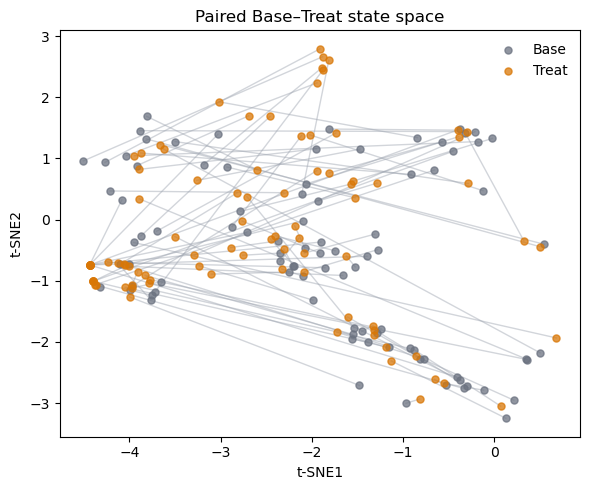

Saved: results/02_descriptive/fig3_state_space.png


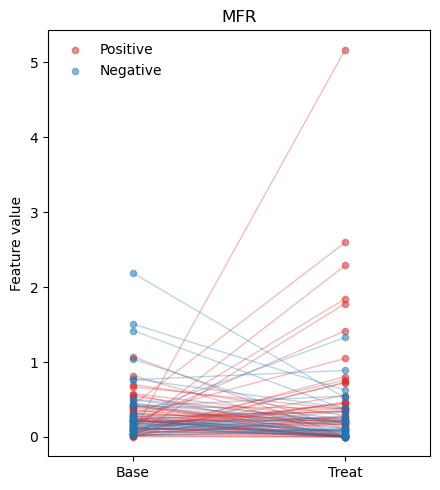

Saved: results/02_descriptive/fig3_paired_mfr.png


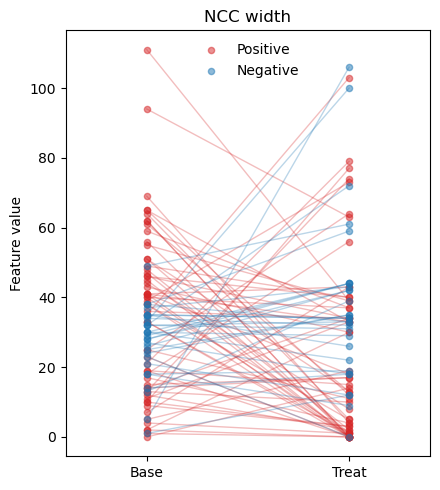

Saved: results/02_descriptive/fig3_paired_ncc_width.png


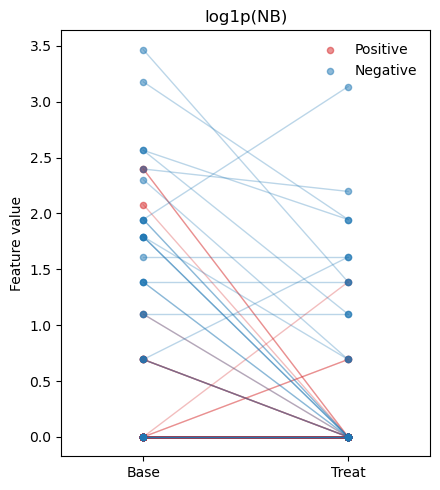

Saved: results/02_descriptive/fig3_paired_network_bursts.png


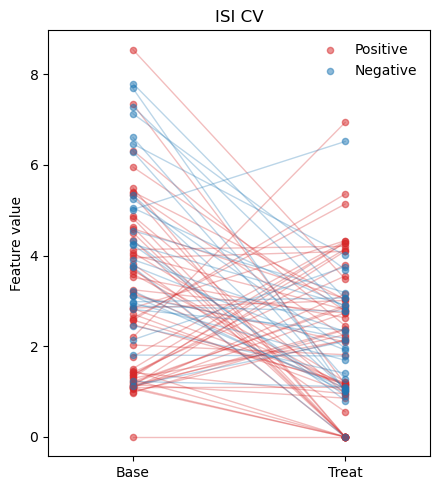

Saved: results/02_descriptive/fig3_paired_isi_cv.png


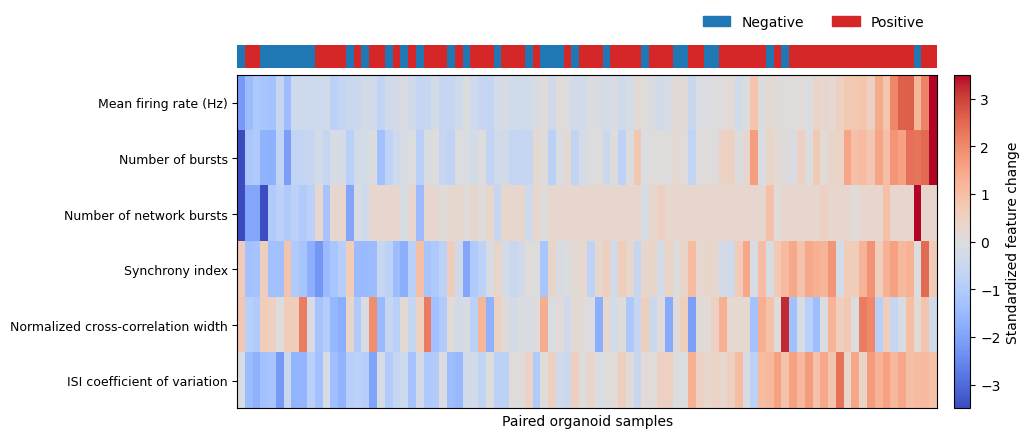

Saved: results/02_descriptive/fig3_delta_heatmap.png


In [5]:
fig, ax = plt.subplots(figsize=(6, 5))
paired_state_space_panel(ax, retained_raw_features)
ax.legend(frameon=False, loc="best")
fig.tight_layout()
save_png(fig, FIG3_DIR, "fig3_state_space")

slope_names = ["mfr", "ncc_width", "network_bursts", "isi_cv"]
for feature, name in zip(FIG3_SLOPE_FEATURES, slope_names):
    fig, ax = plt.subplots(figsize=(4.5, 5))
    class_colored_slope_plot(ax, feature, show_legend=True)
    ax.set_title(DISPLAY_TITLE_MAP[feature])
    ax.set_ylabel("Feature value")
    fig.tight_layout()
    save_png(fig, FIG3_DIR, f"fig3_paired_{name}")

mat, feature_names, order = ordered_heatmap_components(FIG3_HEATMAP_FEATURES)
ordered_classes = paired_df["class"].astype(str).iloc[order].tolist()
fig, ax = plt.subplots(figsize=(11, 4.5))
image, _ = anonymized_delta_heatmap(ax, FIG3_HEATMAP_FEATURES, order=order)
image.set_clim(-3.5, 3.5)
short_heatmap_labels = {
    "Mean Firing Rate (Hz)": "Mean firing rate (Hz)",
    "Number of Bursts": "Number of bursts",
    "Number of Network Bursts": "Number of network bursts",
    "Synchrony Index": "Synchrony index",
    "Width at Half Height of Normalized Cross-Correlation": "Normalized cross-correlation width",
    "ISI Coefficient of Variation - Avg": "ISI coefficient of variation",
}
ax.set_yticklabels([short_heatmap_labels[name] for name in feature_names], fontsize=9)
ax.set_xlabel("Paired organoid samples")
strip = ax.inset_axes([0, 1.02, 1, 0.07])
class_annotation_strip(strip, ordered_classes)
strip.set_ylabel("")
from matplotlib.patches import Patch
strip.legend(handles=[Patch(color=CLASS_COLOR[c], label=c) for c in ["Negative", "Positive"]],
             loc="lower right", bbox_to_anchor=(1, 1.15), ncol=2, frameon=False)
fig.colorbar(image, ax=ax, pad=0.02).set_label("Standardized feature change")
fig.tight_layout()
save_png(fig, FIG3_DIR, "fig3_delta_heatmap")
